# Chapter 6: Decision Trees — Practice Notebook

Decision Trees are versatile Machine Learning algorithms capable of performing both **classification** and **regression** tasks, and even multioutput tasks. They are intuitive, require virtually no feature scaling, and serve as the core building blocks for powerful ensemble algorithms like **Random Forests**.

In [1]:
import sys
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

# Plotting configuration
%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Helper paths
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def image_path(fig_id):
    return os.path.join(IMAGES_PATH, fig_id)

# Ensure Graphviz bin is in PATH for shell commands (!dot)
tools_bin = os.path.abspath(os.path.join(PROJECT_ROOT_DIR, "..", "..", ".tools", "graphviz", "Graphviz-16.1.0-win64", "bin"))
if os.path.exists(tools_bin) and tools_bin not in os.environ["PATH"]:
    os.environ["PATH"] = tools_bin + os.pathsep + os.environ["PATH"]


## 1. Training and Visualizing a Decision Tree (Figure 6-1)

A Decision Tree makes predictions by breaking down a complex decision into a series of **binary if-then questions** based on feature thresholds.

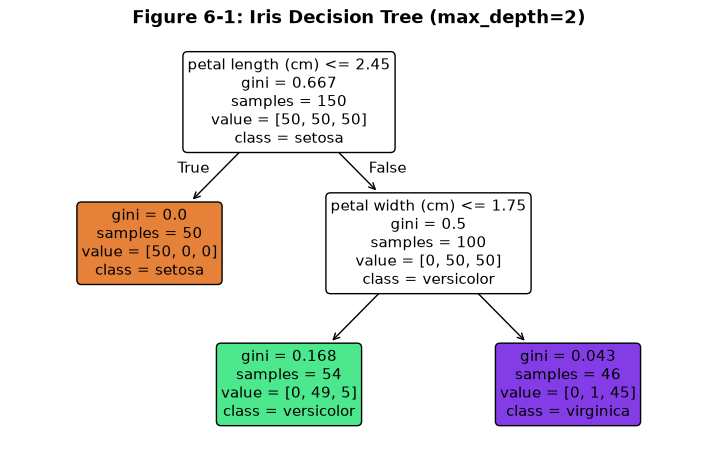

In [2]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_graphviz, plot_tree

# 1. Load Iris data (Petal length and Petal width)
iris = load_iris()
X = iris.data[:, 2:]  # petal length, petal width
y = iris.target

# 2. Train Decision Tree Classifier with max_depth=2
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

# 3. Export to Graphviz DOT definition file
dot_file = image_path("iris_tree.dot")
export_graphviz(
    tree_clf,
    out_file=dot_file,
    feature_names=iris.feature_names[2:],
    class_names=iris.target_names,
    rounded=True,
    filled=True
)

# 4. Visualize the tree inline using Scikit-Learn's plot_tree
plt.figure(figsize=(9, 5.5))
plot_tree(
    tree_clf,
    feature_names=iris.feature_names[2:],
    class_names=iris.target_names,
    rounded=True,
    filled=True,
    fontsize=11
)
plt.title("Figure 6-1: Iris Decision Tree (max_depth=2)", fontsize=13, weight="bold")
plt.show()


**What's going on in Figure 6-1 (How to Read a Node):**
* **Root Node (Top)**: Checks if `petal length <= 2.45 cm`.
  - If **True** (left branch) $\to$ reaches a leaf node where all 50 samples are *Setosa* (`gini = 0.0`). Classification stops immediately!
  - If **False** (right branch) $\to$ checks `petal width <= 1.75 cm`.
* **`samples`**: Number of training instances reaching this node.
* **`value`**: Distribution of classes `[Setosa, Versicolor, Virginica]` in that node.
* **`gini` (Gini Impurity)**: Measures how "mixed" the node is:
  - **`gini = 0.0` (Pure node)**: All instances belong to a single class.
  - Lower Gini means a cleaner, more confident split.
* **Color Intensity**: Darker color indicates a purer node with higher confidence in that class.

## 2. Converting the `.dot` File to Image Formats (PNG, PDF, SVG)

`export_graphviz()` creates an `iris_tree.dot` file. You can convert it to various image/document formats using Graphviz's command-line tool `dot`:

```bash
# Textbook CLI syntax:
$ dot -Tpng iris_tree.dot -o iris_tree.png  # Convert to PNG
$ dot -Tpdf iris_tree.dot -o iris_tree.pdf  # Convert to PDF
$ dot -Tsvg iris_tree.dot -o iris_tree.svg  # Convert to SVG
```

✔ Converted iris_tree.dot to:
  - images/decision_trees/iris_tree.png
  - images/decision_trees/iris_tree.pdf
  - images/decision_trees/iris_tree.svg


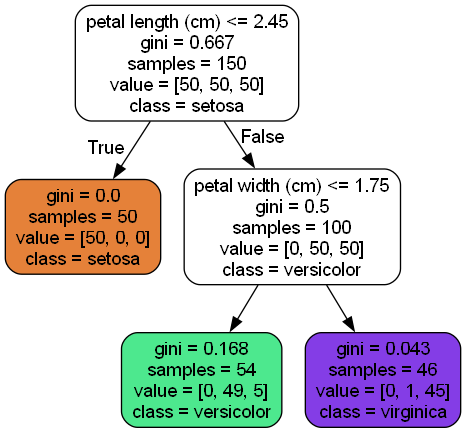

In [3]:
# Convert .dot to PNG, PDF, and SVG using the dot CLI tool
!dot -Tpng images/decision_trees/iris_tree.dot -o images/decision_trees/iris_tree.png
!dot -Tpdf images/decision_trees/iris_tree.dot -o images/decision_trees/iris_tree.pdf
!dot -Tsvg images/decision_trees/iris_tree.dot -o images/decision_trees/iris_tree.svg

print("✔ Converted iris_tree.dot to:")
print("  - images/decision_trees/iris_tree.png")
print("  - images/decision_trees/iris_tree.pdf")
print("  - images/decision_trees/iris_tree.svg")

# Display the converted PNG image inline
from IPython.display import Image, display
display(Image(filename=image_path("iris_tree.png"), width=550))


## 3. Estimating Class Probabilities (Figure 6-2)

A Decision Tree estimates the probability that an instance belongs to a particular class $k$ by:
1. **Traversing the tree** to find the leaf node for the instance.
2. **Calculating the percentage (fraction)** of training examples in that leaf:
   $$P(Y = k \mid \mathbf{x}) = \frac{\text{examples of class } k \text{ in leaf}}{\text{total examples in leaf}}$$

### Example:
Suppose you find a flower whose petals are **5 cm long** and **1.5 cm wide**:
* It traverses the tree and lands in the **depth-2 left node** (`value = [0, 49, 5]`, total = 54 samples).
* **Iris-Setosa**: $0 / 54 = 0\%$
* **Iris-Versicolor**: $49 / 54 \approx 90.7\%$
* **Iris-Virginica**: $5 / 54 \approx 9.3\%$
* Predicted class is **Iris-Versicolor (class 1)**.

In [4]:
flower = [[5, 1.5]]
proba = tree_clf.predict_proba(flower)
pred = tree_clf.predict(flower)

print("tree_clf.predict_proba([[5, 1.5]]):\n", proba)
print("tree_clf.predict([[5, 1.5]]):\n", pred)
print(f"\nPredicted class: {pred[0]} ({iris.target_names[pred[0]]})")
print(f"Estimated probabilities:")
print(f"  - Iris-Setosa:     {proba[0][0]:.1%}")
print(f"  - Iris-Versicolor: {proba[0][1]:.1%}")
print(f"  - Iris-Virginica:  {proba[0][2]:.1%}")


tree_clf.predict_proba([[5, 1.5]]):
 [[0.         0.90740741 0.09259259]]
tree_clf.predict([[5, 1.5]]):
 [1]

Predicted class: 1 (versicolor)
Estimated probabilities:
  - Iris-Setosa:     0.0%
  - Iris-Versicolor: 90.7%
  - Iris-Virginica:  9.3%


tree_clf.predict_proba([[6, 1.5]]): [[0.         0.90740741 0.09259259]]
tree_clf.predict([[6, 1.5]]): [1]


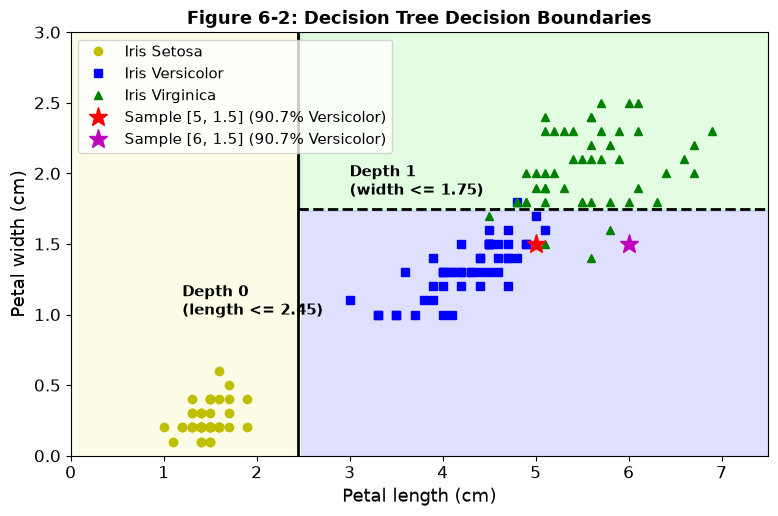

In [5]:
from matplotlib.colors import ListedColormap

# Test sample [6, 1.5] - notice probabilities are identical because it falls in the same leaf rectangle!
flower2 = [[6, 1.5]]
print("tree_clf.predict_proba([[6, 1.5]]):", tree_clf.predict_proba(flower2))
print("tree_clf.predict([[6, 1.5]]):", tree_clf.predict(flower2))

# Plot Figure 6-2: Decision Boundaries
plt.figure(figsize=(9, 5.5))
axes = [0, 7.5, 0, 3]
x1s = np.linspace(axes[0], axes[1], 100)
x2s = np.linspace(axes[2], axes[3], 100)
x1, x2 = np.meshgrid(x1s, x2s)
X_new = np.c_[x1.ravel(), x2.ravel()]
y_pred = tree_clf.predict(X_new).reshape(x1.shape)
custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)

# Training instances
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris Setosa")
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris Versicolor")
plt.plot(X[:, 0][y==2], X[:, 1][y==2], "g^", label="Iris Virginica")

# Decision boundaries
plt.plot([2.45, 2.45], [0, 3], "k-", linewidth=2)
plt.plot([2.45, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.text(1.20, 1.0, "Depth 0\n(length <= 2.45)", fontsize=11, weight="bold")
plt.text(3.0, 1.85, "Depth 1\n(width <= 1.75)", fontsize=11, weight="bold")

# Mark the two test samples
plt.plot(5, 1.5, "r*", markersize=14, label="Sample [5, 1.5] (90.7% Versicolor)")
plt.plot(6, 1.5, "m*", markersize=14, label="Sample [6, 1.5] (90.7% Versicolor)")

plt.xlabel("Petal length (cm)", fontsize=13)
plt.ylabel("Petal width (cm)", fontsize=13)
plt.axis(axes)
plt.legend(loc="upper left", fontsize=10.5)
plt.title("Figure 6-2: Decision Tree Decision Boundaries", fontsize=13, weight="bold")
plt.savefig(image_path("decision_tree_decision_boundaries.png"), dpi=300, bbox_inches="tight")
plt.show()


## 4. Decision Tree Regression (Figure 6-4 & 6-5)

Decision Trees are also capable of performing **regression tasks** (predicting a continuous continuous number instead of a class label).

### How Decision Tree Regression Works:
* **Classification vs. Regression**:
  - In **Classification**, a leaf predicts a **class category** (and probability based on class ratios).
  - In **Regression**, a leaf predicts a **single numeric value**: the **average (mean) target value $\hat{y}$** of all training instances in that leaf!
* **Cost function**:
  - Instead of trying to minimize Gini Impurity, the CART algorithm splits the data to minimize the **Mean Squared Error (MSE)** of each leaf:
    $$\text{MSE}_{\text{node}} = \frac{1}{m_{\text{node}}} \sum_{i \in \text{node}} (\hat{y}_{\text{node}} - y^{(i)})^2$$

In [6]:
from sklearn.tree import DecisionTreeRegressor

# 1. Create a noisy quadratic dataset (from Chapter 6)
np.random.seed(42)
m = 200
X_reg = np.random.rand(m, 1)
y_reg = 4 * (X_reg - 0.5) ** 2 + np.random.randn(m, 1) / 10

# 2. Train Decision Tree Regressor with max_depth=2
tree_reg1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg1.fit(X_reg, y_reg)

# Also train max_depth=3 for comparison
tree_reg2 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg2.fit(X_reg, y_reg)

# 3. Predict for a new instance, say x = 0.6
x_new = np.array([[0.6]])
pred = tree_reg1.predict(x_new)
print(f"Predicted value for x = 0.6 (max_depth=2): {pred[0]:.4f}")


Predicted value for x = 0.6 (max_depth=2): 0.1106


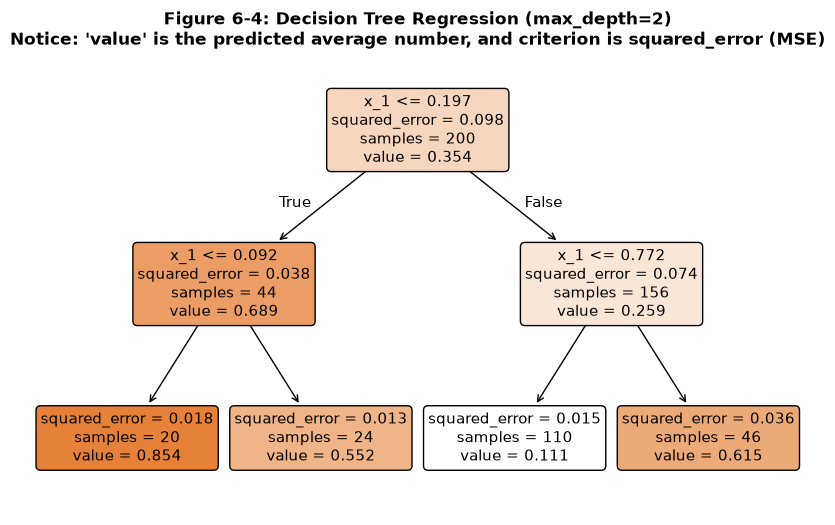

In [7]:
# Visualize the regression tree structure (Figure 6-4)
plt.figure(figsize=(10, 6))
plot_tree(
    tree_reg1,
    feature_names=["x_1"],
    rounded=True,
    filled=True,
    fontsize=11
)
plt.title("Figure 6-4: Decision Tree Regression (max_depth=2)\nNotice: 'value' is the predicted average number, and criterion is squared_error (MSE)", fontsize=12, weight="bold")
plt.savefig(image_path("tree_reg_structure.png"), dpi=300, bbox_inches="tight")
plt.show()


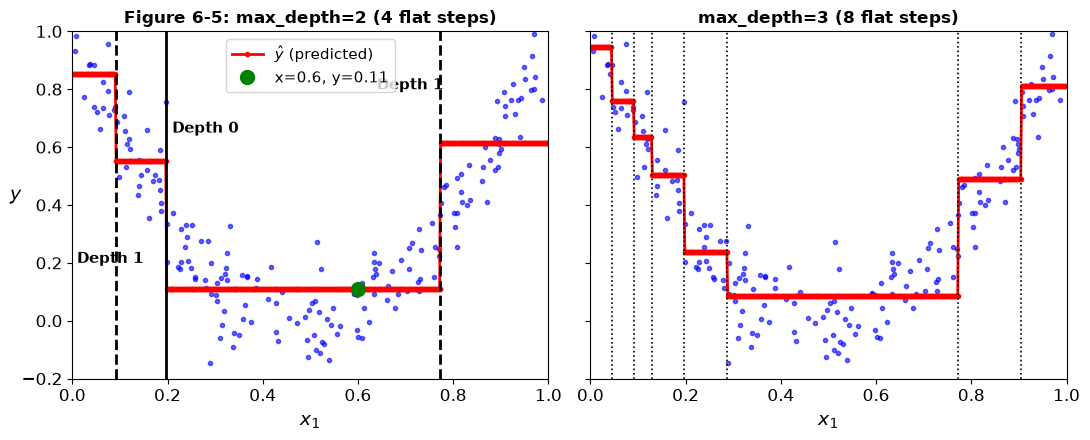

In [8]:
# Plot Figure 6-5: Predictions of Decision Tree regression models
def plot_regression_predictions(tree_reg, X, y, axes=[0, 1, -0.2, 1], ylabel="$y$"):
    x1 = np.linspace(axes[0], axes[1], 500).reshape(-1, 1)
    y_pred = tree_reg.predict(x1)
    plt.axis(axes)
    plt.xlabel("$x_1$", fontsize=14)
    if ylabel:
        plt.ylabel(ylabel, fontsize=14, rotation=0)
    plt.plot(X, y, "b.", alpha=0.6)
    plt.plot(x1, y_pred, "r.-", linewidth=2, label=r"$\hat{y}$ (predicted)")

fig, axes = plt.subplots(ncols=2, figsize=(11, 4.5), sharey=True)

# Left plot: max_depth=2
plt.sca(axes[0])
plot_regression_predictions(tree_reg1, X_reg, y_reg)
for split, style in ((0.1973, "k-"), (0.0917, "k--"), (0.7718, "k--")):
    plt.plot([split, split], [-0.2, 1], style, linewidth=2)
plt.text(0.21, 0.65, "Depth 0", fontsize=11, weight="bold")
plt.text(0.01, 0.2, "Depth 1", fontsize=11, weight="bold")
plt.text(0.64, 0.8, "Depth 1", fontsize=11, weight="bold")
plt.plot(0.6, pred[0], "go", markersize=10, label=f"x=0.6, y={pred[0]:.2f}")
plt.legend(loc="upper center", fontsize=11)
plt.title("Figure 6-5: max_depth=2 (4 flat steps)", fontsize=12, weight="bold")

# Right plot: max_depth=3
plt.sca(axes[1])
plot_regression_predictions(tree_reg2, X_reg, y_reg, ylabel=None)
for split in (0.1973, 0.0917, 0.7718, 0.0458, 0.1298, 0.2873, 0.9040):
    plt.plot([split, split], [-0.2, 1], "k:", linewidth=1.2)
plt.title("max_depth=3 (8 flat steps)", fontsize=12, weight="bold")

plt.tight_layout()
plt.savefig(image_path("decision_tree_regression_predictions.png"), dpi=300, bbox_inches="tight")
plt.show()


## 5. Model Instability: Sensitivity to Rotation and Variance (Figures 6-7 & 6-8)

Decision Trees have two major limitations regarding stability:
1. **Orthogonal Splits (Axis-Aligned)**: Decision boundaries are always perpendicular to a feature axis. If you rotate or flip the data, the tree cannot draw a simple diagonal line—it must construct an unnecessarily complex **staircase**.
2. **High Variance**: Decision Trees are extremely sensitive to small fluctuations in the training set. A tiny change in variance or adding/removing a few data points can produce a radically different tree.

*(In practice, we use **PCA** to align orientations and **Random Forests** to average away high variance!)*

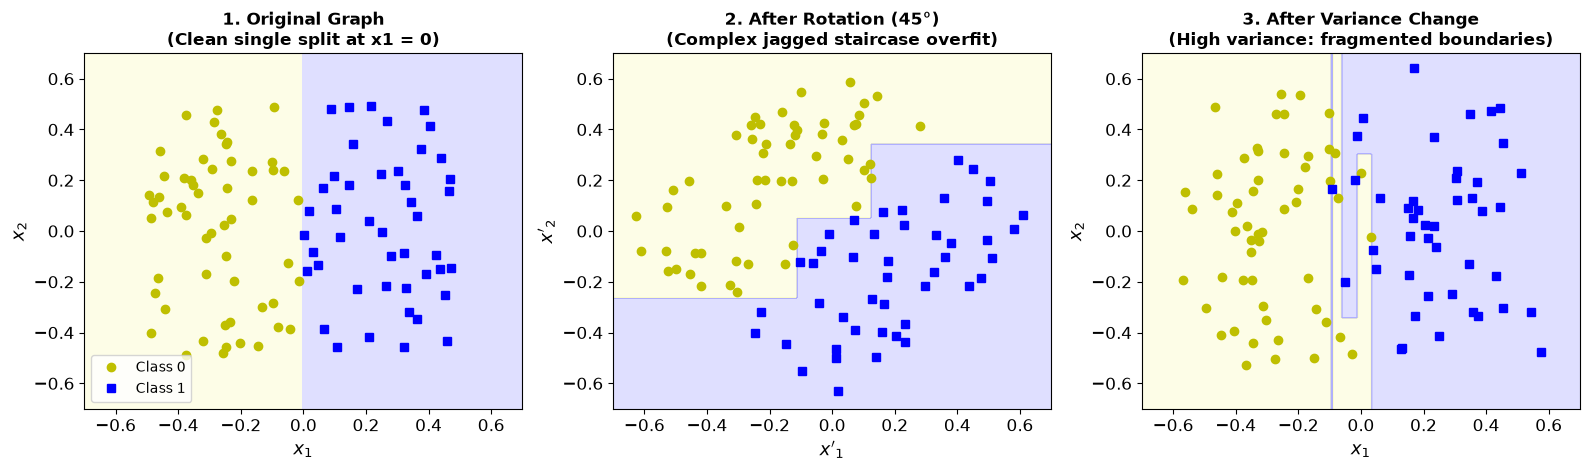

In [9]:
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import ListedColormap

# Helper function to plot 2D decision boundary
def plot_decision_boundary(clf, X, y, axes=[-0.7, 0.7, -0.7, 0.7], xlabel="$x_1$", ylabel="$x_2$"):
    x1s = np.linspace(axes[0], axes[1], 250)
    x2s = np.linspace(axes[2], axes[3], 250)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(['#fafab0', '#9898ff'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Class 0")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Class 1")
    plt.axis(axes)
    plt.xlabel(xlabel, fontsize=13)
    plt.ylabel(ylabel, fontsize=13)

# --- 1. Original Dataset (linearly separable along x1) ---
np.random.seed(6)
Xs = np.random.rand(100, 2) - 0.5
ys = (Xs[:, 0] > 0).astype(np.int64)

tree_orig = DecisionTreeClassifier(random_state=42)
tree_orig.fit(Xs, ys)

# --- 2. Rotated Dataset (45-degree rotation) ---
angle = np.pi / 4
rotation_matrix = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
Xsr = Xs.dot(rotation_matrix)

tree_rot = DecisionTreeClassifier(random_state=42)
tree_rot.fit(Xsr, ys)

# --- 3. Variance Change (Adding small variance/noise to test high variance instability) ---
np.random.seed(42)
Xsv = Xs + np.random.normal(0, 0.08, Xs.shape)
tree_var = DecisionTreeClassifier(random_state=42)
tree_var.fit(Xsv, ys)

# Plotting all 3 results in one figure
fig, axes = plt.subplots(ncols=3, figsize=(16, 4.8))

# Subplot 1: Original
plt.sca(axes[0])
plot_decision_boundary(tree_orig, Xs, ys)
plt.title("1. Original Graph\n(Clean single split at x1 = 0)", fontsize=12, weight="bold")
plt.legend(loc="lower left", fontsize=10)

# Subplot 2: After Rotation
plt.sca(axes[1])
plot_decision_boundary(tree_rot, Xsr, ys, xlabel="$x'_1$", ylabel="$x'_2$")
plt.title("2. After Rotation (45°)\n(Complex jagged staircase overfit)", fontsize=12, weight="bold")

# Subplot 3: After Variance Change
plt.sca(axes[2])
plot_decision_boundary(tree_var, Xsv, ys)
plt.title("3. After Variance Change\n(High variance: fragmented boundaries)", fontsize=12, weight="bold")

plt.tight_layout()
plt.savefig(image_path("decision_tree_instability_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
